In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [9]:
import os
import pywt
import gc
import cv2
import time
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torchvision. transforms as transforms

from PIL import Image
from tqdm import tqdm

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from torch.utils.data import Dataset, DataLoader

from torchvision.models import (
    efficientnet_b4,
    EfficientNet_B4_Weights
)

In [11]:
# ============================================================
# DATASET PATHS
# ============================================================

import os
import torch

DATASET_ROOT = "/kaggle/input/deepfake-aligned-faces-5-frames"

REAL_PATH = os.path.join(DATASET_ROOT, "original")
FAKE_PATH = os.path.join(DATASET_ROOT, "Deepfakes")

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("="*60)
print("DEVICE :", device)
print("REAL PATH :", REAL_PATH)
print("FAKE PATH :", FAKE_PATH)
print("="*60)

DEVICE : cuda
REAL PATH : /kaggle/input/deepfake-aligned-faces-5-frames/original
FAKE PATH : /kaggle/input/deepfake-aligned-faces-5-frames/Deepfakes


In [21]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [24]:
import os

print(os.listdir("/kaggle/input/datasets"))

['srujanamannepuli']


In [25]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [26]:
import os

print(os.listdir("/kaggle/input/datasets/srujanamannepuli"))

['deepfake-aligned-faces-5-frames']


In [28]:
import os
import torch

DATASET_ROOT = "/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces"

REAL_PATH = os.path.join(DATASET_ROOT, "original")
FAKE_PATH = os.path.join(DATASET_ROOT, "Deepfakes")

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("REAL Exists :", os.path.exists(REAL_PATH))
print("FAKE Exists :", os.path.exists(FAKE_PATH))

print("REAL Videos :", len(os.listdir(REAL_PATH)))
print("FAKE Videos :", len(os.listdir(FAKE_PATH)))

REAL Exists : True
FAKE Exists : True
REAL Videos : 500
FAKE Videos : 500


In [29]:
# ============================================================
# CELL 3 : LOAD ALL VIDEOS
# ============================================================

import os
import numpy as np

video_names = []
video_labels = []

# ----------------------------
# REAL VIDEOS
# ----------------------------
for video in sorted(os.listdir(REAL_PATH)):
    video_path = os.path.join(REAL_PATH, video)

    if os.path.isdir(video_path):
        video_names.append(video_path)
        video_labels.append(0)

# ----------------------------
# FAKE VIDEOS
# ----------------------------
for video in sorted(os.listdir(FAKE_PATH)):
    video_path = os.path.join(FAKE_PATH, video)

    if os.path.isdir(video_path):
        video_names.append(video_path)
        video_labels.append(1)

video_names = np.array(video_names)
video_labels = np.array(video_labels)

print("="*60)
print("TOTAL VIDEOS :", len(video_names))
print("REAL VIDEOS  :", np.sum(video_labels==0))
print("FAKE VIDEOS  :", np.sum(video_labels==1))
print("="*60)

TOTAL VIDEOS : 1000
REAL VIDEOS  : 500
FAKE VIDEOS  : 500


In [30]:
# ============================================================
# BUILD 3 FRAME SAMPLES
# ============================================================

def build_3frame_samples(video_paths, video_labels):

    samples = []

    for video_path, label in zip(video_paths, video_labels):

        frames = sorted([
            f for f in os.listdir(video_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        if len(frames) == 0:
            continue

        # First, Middle, Last
        indices = [
            0,
            len(frames)//2,
            len(frames)-1
        ]

        for idx in indices:

            frame_path = os.path.join(
                video_path,
                frames[idx]
            )

            samples.append(
                (
                    frame_path,
                    label,
                    os.path.basename(video_path)
                )
            )

    return samples

In [31]:
# ============================================================
# BUILD 5 FRAME SAMPLES
# ============================================================

def build_frame_samples(video_paths, video_labels):

    samples = []

    for video_path, label in zip(video_paths, video_labels):

        frames = sorted([
            f for f in os.listdir(video_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        for frame in frames:

            frame_path = os.path.join(
                video_path,
                frame
            )

            samples.append(
                (
                    frame_path,
                    label,
                    os.path.basename(video_path)
                )
            )

    return samples

In [32]:
train_samples = build_3frame_samples(video_names, video_labels)
val_samples = build_frame_samples(video_names, video_labels)

print(len(train_samples))
print(len(val_samples))

3000
4997


In [37]:
# ============================================================
# DWT DATASET
# ============================================================

import pywt
import cv2
from PIL import Image

class DeepfakeDataset(Dataset):

    def __init__(self, samples, transform=None):

        self.samples = samples
        self.transform = transform

    def __len__(self):

        return len(self.samples)

    def apply_dwt(self, image):

        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

        LL, (LH, HL, HH) = pywt.dwt2(gray, 'haar')

        LL = cv2.resize(LL, (224,224))

        LL = cv2.normalize(
            LL,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        )

        LL = LL.astype(np.uint8)

        LL = cv2.cvtColor(
            LL,
            cv2.COLOR_GRAY2RGB
        )

        return LL

    def __getitem__(self, index):

        frame_path, label, video_name = self.samples[index]

        image = Image.open(frame_path).convert("RGB")

        image = np.array(image)

        image = self.apply_dwt(image)

        image = Image.fromarray(image)

        if self.transform is not None:
            image = self.transform(image)

        return image, label, video_name

In [38]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

dataset = DeepfakeDataset(
    train_samples,
    train_transform
)

image, label, video = dataset[0]

print(image.shape)
print(label)
print(video)

torch.Size([3, 224, 224])
0
000


In [39]:
# ============================================================
# IMAGE TRANSFORMS
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

print("Transforms Ready")

Transforms Ready


In [40]:
# ============================================================
# CREATE DWT + EFFICIENTNET-B4 MODEL
# ============================================================

from torchvision.models import (
    efficientnet_b4,
    EfficientNet_B4_Weights
)

def create_model():

    weights = EfficientNet_B4_Weights.DEFAULT

    model = efficientnet_b4(
        weights=weights
    )

    in_features = model.classifier[1].in_features

    model.classifier = nn.Sequential(

        nn.Dropout(0.4),

        nn.Linear(
            in_features,
            2
        )

    )

    return model.to(device)


model = create_model()

print(model)
print("\n✅ EfficientNet-B4 Loaded")

Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 223MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=48, bias=False)
            (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(48, 12, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(12, 48, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActiv

In [42]:
dummy = torch.randn(
    2,
    3,
    224,
    224
).to(device)

out = model(dummy)

print(out.shape)

torch.Size([2, 2])


In [44]:
model = create_model()

In [45]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

print("Loss, Optimizer & Scheduler Ready")

Loss, Optimizer & Scheduler Ready


In [46]:
# ============================================================
# CREATE DATALOADERS
# ============================================================

from sklearn.model_selection import StratifiedKFold

kf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    kf.split(video_names, video_labels)
)

train_samples = build_3frame_samples(
    video_names[train_idx],
    video_labels[train_idx]
)

val_samples = build_frame_samples(
    video_names[val_idx],
    video_labels[val_idx]
)

train_dataset = DeepfakeDataset(
    train_samples,
    train_transform
)

val_dataset = DeepfakeDataset(
    val_samples,
    val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("="*60)
print("Train Samples :", len(train_dataset))
print("Validation Samples :", len(val_dataset))
print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))
print("="*60)

Train Samples : 2700
Validation Samples : 500
Train Batches : 169
Validation Batches : 32


In [47]:
# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(model,
                    loader,
                    optimizer,
                    criterion):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels, _ in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def validate(model,
             loader,
             criterion):

    model.eval()

    running_loss = 0.0

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():

        for images, labels, _ in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)

            preds = torch.argmax(outputs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_prob.extend(probs[:,1].cpu().numpy())

    val_loss = running_loss / len(loader)

    acc = accuracy_score(y_true, y_pred)

    precision = precision_score(y_true, y_pred)

    recall = recall_score(y_true, y_pred)

    f1 = f1_score(y_true, y_pred)

    auc = roc_auc_score(y_true, y_prob)

    return (
    val_loss,
    acc,
    precision,
    recall,
    f1,
    auc,
    y_true,
    y_pred
    y_prob
    )

In [54]:
# ============================================================
# 10-FOLD CROSS VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix
import numpy as np

NUM_FOLDS = 10
EPOCHS = 10

kf = StratifiedKFold(
    n_splits=NUM_FOLDS,
    shuffle=True,
    random_state=42
)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(video_names, video_labels), start=1
):

    print("\n" + "="*70)
    print(f"FOLD {fold}/{NUM_FOLDS}")
    print("="*70)

    # -----------------------------
    # Build Samples
    # -----------------------------
    train_samples = build_3frame_samples(
        video_names[train_idx],
        video_labels[train_idx]
    )

    val_samples = build_frame_samples(
        video_names[val_idx],
        video_labels[val_idx]
    )

    # -----------------------------
    # Dataset
    # -----------------------------
    train_dataset = DeepfakeDataset(
        train_samples,
        train_transform
    )

    val_dataset = DeepfakeDataset(
        val_samples,
        val_transform
    )

    # -----------------------------
    # DataLoader
    # -----------------------------
    train_loader = DataLoader(
        train_dataset,
        batch_size=16,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=16,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    # -----------------------------
    # Model
    # -----------------------------
    model = create_model()

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    best_acc = 0.0
    best_loss = 0.0
    best_precision = 0.0
    best_recall = 0.0
    best_f1 = 0.0
    best_auc = 0.0
    best_cm = None

    for epoch in range(EPOCHS):

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion
        )

        (
            val_loss,
            val_acc,
            precision,
            recall,
            f1,
            auc,
            y_true,
            y_pred
        ) = validate(
            model,
            val_loader,
            criterion
        )

        scheduler.step()

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc*100:.2f}%"
        )

        if val_acc > best_acc:

            best_acc = val_acc
            best_loss = val_loss
            best_precision = precision
            best_recall = recall
            best_f1 = f1
            best_auc = auc

            best_cm = confusion_matrix(
                y_true,
                y_pred
            )

            torch.save(
                model.state_dict(),
                f"best_fold_{fold}.pth"
            )

    fold_results.append(best_acc)

    print("\n"+"="*60)
    print(f"FOLD {fold} RESULTS")
    print("="*60)

    print(f"Accuracy        : {best_acc*100:.2f}%")
    print(f"Validation Loss : {best_loss:.4f}")
    print(f"Precision       : {best_precision:.4f}")
    print(f"Recall          : {best_recall:.4f}")
    print(f"F1 Score        : {best_f1:.4f}")
    print(f"AUC             : {best_auc:.4f}")

    print("\nConfusion Matrix")
    print(best_cm)

print("\n"+"="*70)
print("FINAL 10-FOLD RESULTS")
print("="*70)

for i, acc in enumerate(fold_results):

    print(
        f"Fold {i+1} : {acc*100:.2f}%"
    )

print("-"*70)

print(
    f"Mean Accuracy : {np.mean(fold_results)*100:.2f}%"
)

print(
    f"Std Deviation : {np.std(fold_results)*100:.2f}%"
)


FOLD 1/10
Epoch 01/10 | Train Acc: 62.63% | Val Acc: 74.20%
Epoch 02/10 | Train Acc: 79.52% | Val Acc: 90.00%
Epoch 03/10 | Train Acc: 86.96% | Val Acc: 93.00%
Epoch 04/10 | Train Acc: 91.78% | Val Acc: 93.40%
Epoch 05/10 | Train Acc: 93.30% | Val Acc: 94.00%
Epoch 06/10 | Train Acc: 93.33% | Val Acc: 93.80%
Epoch 07/10 | Train Acc: 93.15% | Val Acc: 94.40%
Epoch 08/10 | Train Acc: 94.37% | Val Acc: 94.60%
Epoch 09/10 | Train Acc: 94.52% | Val Acc: 94.00%
Epoch 10/10 | Train Acc: 94.89% | Val Acc: 93.80%

FOLD 1 RESULTS
Accuracy        : 94.60%
Validation Loss : 0.1340
Precision       : 0.9745
Recall          : 0.9160
F1 Score        : 0.9443
AUC             : 0.9897

Confusion Matrix
[[244   6]
 [ 21 229]]

FOLD 2/10
Epoch 01/10 | Train Acc: 62.74% | Val Acc: 79.60%
Epoch 02/10 | Train Acc: 80.15% | Val Acc: 87.00%
Epoch 03/10 | Train Acc: 87.56% | Val Acc: 90.20%
Epoch 04/10 | Train Acc: 90.48% | Val Acc: 91.60%
Epoch 05/10 | Train Acc: 91.63% | Val Acc: 91.80%
Epoch 06/10 | Train A

In [56]:
fold_results = [

    {
        "Fold": 1,
        "Accuracy": 94.60,
        "Loss": 0.1340,
        "Precision": 0.9745,
        "Recall": 0.9160,
        "F1": 0.9443,
        "AUC": 0.9897
    },

    {
        "Fold": 2,
        "Accuracy": 92.60,
        "Loss": 0.1558,
        "Precision": 0.9347,
        "Recall": 0.9160,
        "F1": 0.9253,
        "AUC": 0.9871
    },

    {
        "Fold": 3,
        "Accuracy": 93.40,
        "Loss": 0.1790,
        "Precision": 0.9657,
        "Recall": 0.9000,
        "F1": 0.9317,
        "AUC": 0.9819
    },

    {
        "Fold": 4,
        "Accuracy": 90.80,
        "Loss": 0.2106,
        "Precision": 0.9397,
        "Recall": 0.8720,
        "F1": 0.9046,
        "AUC": 0.9750
    },

    {
        "Fold": 5,
        "Accuracy": 93.20,
        "Loss": 0.1957,
        "Precision": 0.9500,
        "Recall": 0.9120,
        "F1": 0.9306,
        "AUC": 0.9804
    },

    {
        "Fold": 6,
        "Accuracy": 93.80,
        "Loss": 0.1653,
        "Precision": 0.9660,
        "Recall": 0.9080,
        "F1": 0.9361,
        "AUC": 0.9828
    },

    {
        "Fold": 7,
        "Accuracy": 93.99,
        "Loss": 0.1866,
        "Precision": 0.9782,
        "Recall": 0.8996,
        "F1": 0.9372,
        "AUC": 0.9823
    },

    {
        "Fold": 8,
        "Accuracy": 94.18,
        "Loss": 0.1470,
        "Precision": 0.9544,
        "Recall": 0.9274,
        "F1": 0.9407,
        "AUC":  0.9867
    },

    {
        "Fold": 9,
        "Accuracy": 93.00,
        "Loss": 0.1841,
        "Precision": 0.9498,
        "Recall": 0.9080,
        "F1": 0.9284,
        "AUC": 0.9806
    },

    {
        "Fold": 10,
        "Accuracy": 95.60,
        "Loss": 0.1554,
        "Precision": 0.9560,
        "Recall": 0.9560,
        "F1": 0.9560,
        "AUC": 0.9892
    }

]

10-FOLD CROSS-VALIDATION PERFORMANCE


,Fold,Accuracy,Loss,Precision,Recall,F1,AUC
0,1,94.60,0.1340,0.9745,0.9160,0.9443,0.9897
1,2,92.60,0.1558,0.9347,0.9160,0.9253,0.9871
2,3,93.40,0.1790,0.9657,0.9000,0.9317,0.9819
3,4,90.80,0.2106,0.9397,0.8720,0.9046,0.9750
4,5,93.20,0.1957,0.9500,0.9120,0.9306,0.9804
5,6,93.80,0.1653,0.9660,0.9080,0.9361,0.9828
6,7,93.99,0.1866,0.9782,0.8996,0.9372,0.9823
7,8,94.18,0.1470,0.9544,0.9274,0.9407,0.9867
8,9,93.00,0.1841,0.9498,0.9080,0.9284,0.9806
9,10,95.60,0.1554,0.9560,0.9560,0.9560,0.9892


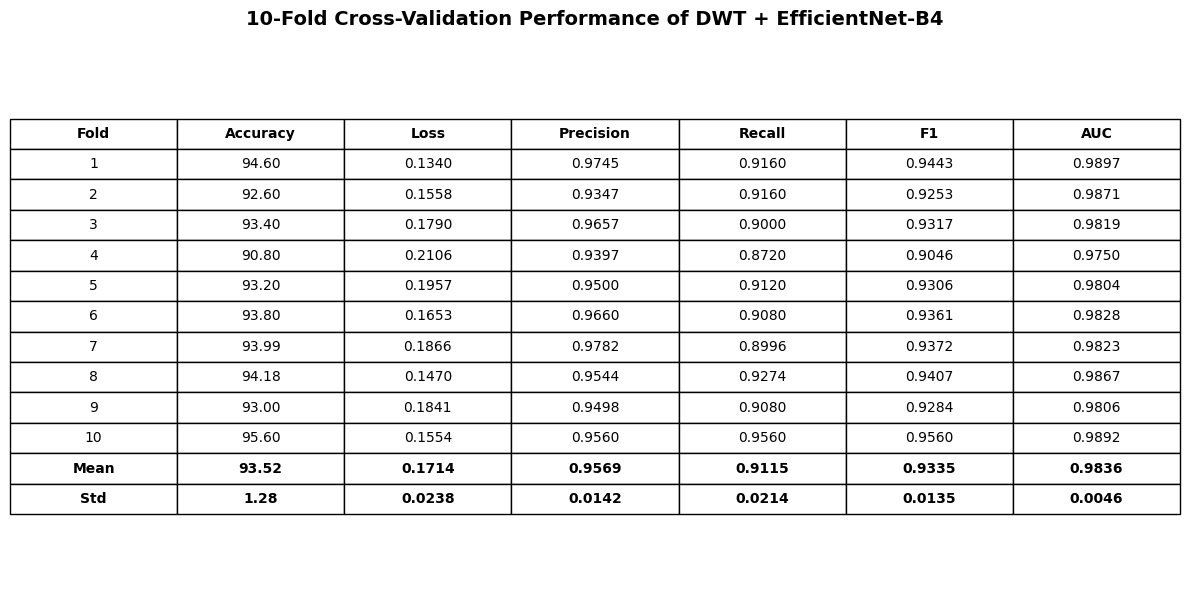


✅ Files Saved Successfully
1. 10_fold_performance_table.png  (300 DPI)
2. 10_fold_performance_table.csv


In [57]:
# ============================================================
# CELL 24 : 10-FOLD RESULTS TABLE + MEAN + STD + SAVE PNG
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Convert fold results to DataFrame
# ------------------------------------------------------------
results_df = pd.DataFrame(fold_results)

# ------------------------------------------------------------
# 2. Calculate Mean and Standard Deviation
# ------------------------------------------------------------
mean_row = {
    "Fold": "Mean",
    "Accuracy": results_df["Accuracy"].mean(),
    "Loss": results_df["Loss"].mean(),
    "Precision": results_df["Precision"].mean(),
    "Recall": results_df["Recall"].mean(),
    "F1": results_df["F1"].mean(),
    "AUC": results_df["AUC"].mean()
}

std_row = {
    "Fold": "Std",
    "Accuracy": results_df["Accuracy"].std(ddof=1),
    "Loss": results_df["Loss"].std(ddof=1),
    "Precision": results_df["Precision"].std(ddof=1),
    "Recall": results_df["Recall"].std(ddof=1),
    "F1": results_df["F1"].std(ddof=1),
    "AUC": results_df["AUC"].std(ddof=1)
}

# ------------------------------------------------------------
# 3. Add Mean and Std rows
# ------------------------------------------------------------
final_table = pd.concat(
    [
        results_df,
        pd.DataFrame([mean_row, std_row])
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 4. Create formatted copy for display
# ------------------------------------------------------------
display_table = final_table.copy()

display_table["Accuracy"] = display_table["Accuracy"].map(
    lambda x: f"{x:.2f}"
)

display_table["Loss"] = display_table["Loss"].map(
    lambda x: f"{x:.4f}"
)

display_table["Precision"] = display_table["Precision"].map(
    lambda x: f"{x:.4f}"
)

display_table["Recall"] = display_table["Recall"].map(
    lambda x: f"{x:.4f}"
)

display_table["F1"] = display_table["F1"].map(
    lambda x: f"{x:.4f}"
)

display_table["AUC"] = display_table["AUC"].map(
    lambda x: f"{x:.4f}"
)

# ------------------------------------------------------------
# 5. Display Table
# ------------------------------------------------------------
print("=" * 90)
print("10-FOLD CROSS-VALIDATION PERFORMANCE")
print("=" * 90)

display(display_table)

# ------------------------------------------------------------
# 6. Create Figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

ax.axis("off")

table = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

# Font size
table.auto_set_font_size(False)
table.set_fontsize(10)

# Adjust table size
table.scale(1, 1.6)

# ------------------------------------------------------------
# 7. Bold Header + Mean + Std rows
# ------------------------------------------------------------
for (row, col), cell in table.get_celld().items():

    # Header
    if row == 0:
        cell.set_text_props(weight="bold")

    # Mean and Std rows
    if row in [len(display_table)-1, len(display_table)]:
        cell.set_text_props(weight="bold")

# ------------------------------------------------------------
# 8. Title
# ------------------------------------------------------------
plt.title(
    "10-Fold Cross-Validation Performance of DWT + EfficientNet-B4",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

# ------------------------------------------------------------
# 9. Save Paper-Quality PNG (300 DPI)
# ------------------------------------------------------------
plt.savefig(
    "10_fold_performance_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. Save numerical results also
# ------------------------------------------------------------
final_table.to_csv(
    "10_fold_performance_table.csv",
    index=False
)

print("\n✅ Files Saved Successfully")
print("1. 10_fold_performance_table.png  (300 DPI)")
print("2. 10_fold_performance_table.csv")

In [58]:
# ============================================================
# PRINT FINAL MEAN ± STANDARD DEVIATION
# ============================================================

mean_accuracy = results_df["Accuracy"].mean()
std_accuracy = results_df["Accuracy"].std(ddof=1)

mean_precision = results_df["Precision"].mean()
mean_recall = results_df["Recall"].mean()
mean_f1 = results_df["F1"].mean()
mean_auc = results_df["AUC"].mean()

print("\n" + "="*60)
print("FINAL 10-FOLD PERFORMANCE SUMMARY")
print("="*60)

print(f"Mean Accuracy       : {mean_accuracy:.2f}%")
print(f"Standard Deviation  : {std_accuracy:.2f}%")
print(f"Accuracy (Mean±Std) : {mean_accuracy:.2f} ± {std_accuracy:.2f}%")

print(f"Mean Precision      : {mean_precision:.4f}")
print(f"Mean Recall         : {mean_recall:.4f}")
print(f"Mean F1 Score       : {mean_f1:.4f}")
print(f"Mean AUC            : {mean_auc:.4f}")

print("="*60)


FINAL 10-FOLD PERFORMANCE SUMMARY
Mean Accuracy       : 93.52%
Standard Deviation  : 1.28%
Accuracy (Mean±Std) : 93.52 ± 1.28%
Mean Precision      : 0.9569
Mean Recall         : 0.9115
Mean F1 Score       : 0.9335
Mean AUC            : 0.9836


In [59]:
from IPython.display import FileLink

display(FileLink("10_fold_performance_table.png"))

/kaggle/working/10_fold_performance_table.png


10-FOLD CROSS-VALIDATION PERFORMANCE


,Fold,Accuracy,Loss,Precision,Recall,F1,AUC
0,1,94.60%,0.1340,0.9745,0.9160,0.9443,0.9897
1,2,92.60%,0.1558,0.9347,0.9160,0.9253,0.9871
2,3,93.40%,0.1790,0.9657,0.9000,0.9317,0.9819
3,4,90.80%,0.2106,0.9397,0.8720,0.9046,0.9750
4,5,93.20%,0.1957,0.9500,0.9120,0.9306,0.9804
5,6,93.80%,0.1653,0.9660,0.9080,0.9361,0.9828
6,7,93.99%,0.1866,0.9782,0.8996,0.9372,0.9823
7,8,94.18%,0.1470,0.9544,0.9274,0.9407,0.9867
8,9,93.00%,0.1841,0.9498,0.9080,0.9284,0.9806
9,10,95.60%,0.1554,0.9560,0.9560,0.9560,0.9892



FINAL 10-FOLD PERFORMANCE SUMMARY
Mean Accuracy             : 93.52%
Accuracy Std Deviation    : 1.28%
Accuracy (Mean ± Std)     : 93.52 ± 1.28%
----------------------------------------------------------------------
Mean Validation Loss      : 0.1714
Loss Std Deviation        : 0.0238
Loss (Mean ± Std)         : 0.1714 ± 0.0238
----------------------------------------------------------------------
Mean Precision            : 0.9569
Precision Std Deviation   : 0.0142
Precision (Mean ± Std)    : 0.9569 ± 0.0142
----------------------------------------------------------------------
Mean Recall               : 0.9115
Recall Std Deviation      : 0.0214
Recall (Mean ± Std)       : 0.9115 ± 0.0214
----------------------------------------------------------------------
Mean F1 Score             : 0.9335
F1 Std Deviation          : 0.0135
F1 (Mean ± Std)           : 0.9335 ± 0.0135
----------------------------------------------------------------------
Mean AUC                  : 0.9836
AUC Std 

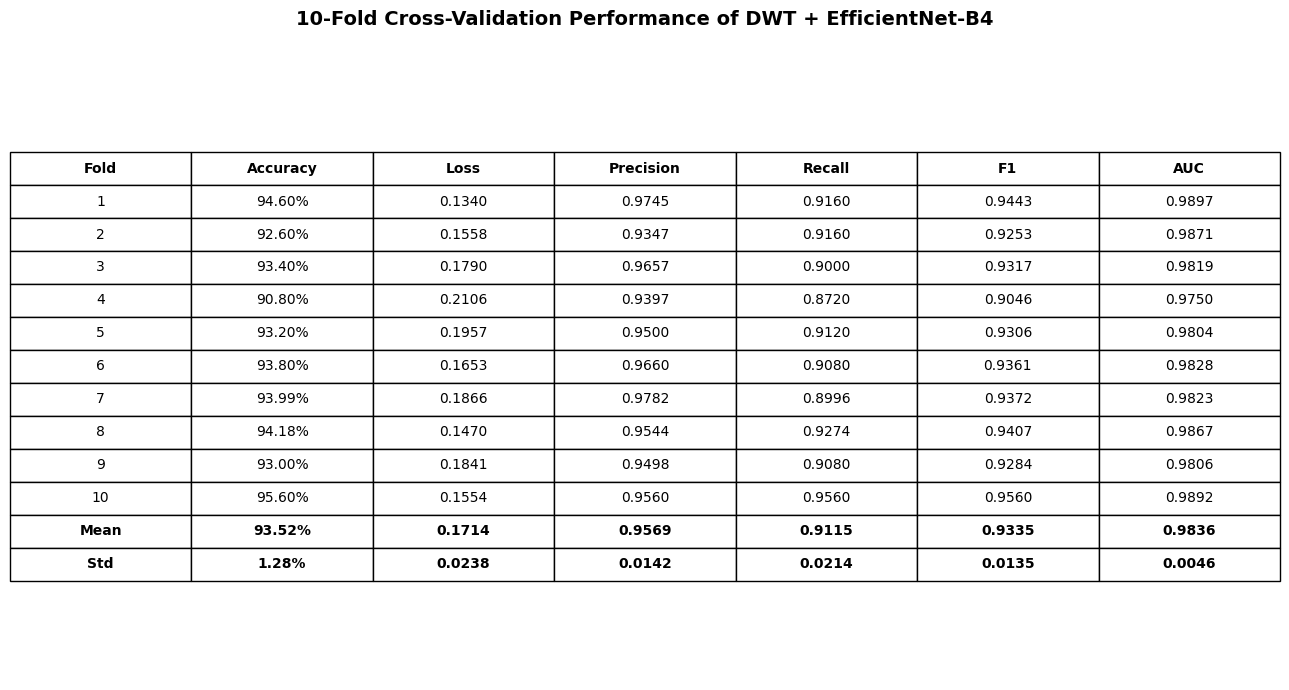


FILES SAVED SUCCESSFULLY:
1. 10_fold_results_mean_std.png
2. 10_fold_results_mean_std.csv
3. 10_fold_statistical_summary.csv

DOWNLOAD FILES:


/kaggle/working/10_fold_results_mean_std.png

/kaggle/working/10_fold_results_mean_std.csv

/kaggle/working/10_fold_statistical_summary.csv

In [60]:
# ============================================================
# COMPLETE 10-FOLD RESULTS TABLE + MEAN + STD + SAVE FILES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. CONVERT MANUALLY ENTERED FOLD RESULTS TO DATAFRAME
# ------------------------------------------------------------

results_df = pd.DataFrame(fold_results)

# Make sure numerical columns are numeric
numeric_cols = [
    "Accuracy",
    "Loss",
    "Precision",
    "Recall",
    "F1",
    "AUC"
]

for col in numeric_cols:
    results_df[col] = pd.to_numeric(
        results_df[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 2. CALCULATE MEAN VALUES
# ------------------------------------------------------------

mean_accuracy = results_df["Accuracy"].mean()
mean_loss = results_df["Loss"].mean()
mean_precision = results_df["Precision"].mean()
mean_recall = results_df["Recall"].mean()
mean_f1 = results_df["F1"].mean()
mean_auc = results_df["AUC"].mean()

# ------------------------------------------------------------
# 3. CALCULATE STANDARD DEVIATION
# Sample SD (ddof=1) across the 10 folds
# ------------------------------------------------------------

std_accuracy = results_df["Accuracy"].std(ddof=1)
std_loss = results_df["Loss"].std(ddof=1)
std_precision = results_df["Precision"].std(ddof=1)
std_recall = results_df["Recall"].std(ddof=1)
std_f1 = results_df["F1"].std(ddof=1)
std_auc = results_df["AUC"].std(ddof=1)

# ------------------------------------------------------------
# 4. CREATE MEAN ROW
# ------------------------------------------------------------

mean_row = {
    "Fold": "Mean",
    "Accuracy": mean_accuracy,
    "Loss": mean_loss,
    "Precision": mean_precision,
    "Recall": mean_recall,
    "F1": mean_f1,
    "AUC": mean_auc
}

# ------------------------------------------------------------
# 5. CREATE STANDARD DEVIATION ROW
# ------------------------------------------------------------

std_row = {
    "Fold": "Std",
    "Accuracy": std_accuracy,
    "Loss": std_loss,
    "Precision": std_precision,
    "Recall": std_recall,
    "F1": std_f1,
    "AUC": std_auc
}

# ------------------------------------------------------------
# 6. ADD MEAN + STD TO FINAL TABLE
# ------------------------------------------------------------

final_table = pd.concat(
    [
        results_df,
        pd.DataFrame([mean_row]),
        pd.DataFrame([std_row])
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 7. CREATE CLEAN DISPLAY TABLE
# ------------------------------------------------------------

display_table = final_table.copy()

display_table["Accuracy"] = display_table["Accuracy"].apply(
    lambda x: f"{x:.2f}%"
)

display_table["Loss"] = display_table["Loss"].apply(
    lambda x: f"{x:.4f}"
)

display_table["Precision"] = display_table["Precision"].apply(
    lambda x: f"{x:.4f}"
)

display_table["Recall"] = display_table["Recall"].apply(
    lambda x: f"{x:.4f}"
)

display_table["F1"] = display_table["F1"].apply(
    lambda x: f"{x:.4f}"
)

display_table["AUC"] = display_table["AUC"].apply(
    lambda x: f"{x:.4f}"
)

# ------------------------------------------------------------
# 8. DISPLAY 10-FOLD TABLE
# ------------------------------------------------------------

print("\n" + "="*90)
print("10-FOLD CROSS-VALIDATION PERFORMANCE")
print("="*90)

display(display_table)

# ------------------------------------------------------------
# 9. PRINT COMPLETE PERFORMANCE SUMMARY
# ------------------------------------------------------------

print("\n" + "="*70)
print("FINAL 10-FOLD PERFORMANCE SUMMARY")
print("="*70)

print(f"Mean Accuracy             : {mean_accuracy:.2f}%")
print(f"Accuracy Std Deviation    : {std_accuracy:.2f}%")
print(
    f"Accuracy (Mean ± Std)     : "
    f"{mean_accuracy:.2f} ± {std_accuracy:.2f}%"
)

print("-"*70)

print(f"Mean Validation Loss      : {mean_loss:.4f}")
print(f"Loss Std Deviation        : {std_loss:.4f}")
print(
    f"Loss (Mean ± Std)         : "
    f"{mean_loss:.4f} ± {std_loss:.4f}"
)

print("-"*70)

print(f"Mean Precision            : {mean_precision:.4f}")
print(f"Precision Std Deviation   : {std_precision:.4f}")
print(
    f"Precision (Mean ± Std)    : "
    f"{mean_precision:.4f} ± {std_precision:.4f}"
)

print("-"*70)

print(f"Mean Recall               : {mean_recall:.4f}")
print(f"Recall Std Deviation      : {std_recall:.4f}")
print(
    f"Recall (Mean ± Std)       : "
    f"{mean_recall:.4f} ± {std_recall:.4f}"
)

print("-"*70)

print(f"Mean F1 Score             : {mean_f1:.4f}")
print(f"F1 Std Deviation          : {std_f1:.4f}")
print(
    f"F1 (Mean ± Std)           : "
    f"{mean_f1:.4f} ± {std_f1:.4f}"
)

print("-"*70)

print(f"Mean AUC                  : {mean_auc:.4f}")
print(f"AUC Std Deviation         : {std_auc:.4f}")
print(
    f"AUC (Mean ± Std)          : "
    f"{mean_auc:.4f} ± {std_auc:.4f}"
)

print("="*70)

# ------------------------------------------------------------
# 10. SAVE NUMERICAL TABLE AS CSV
# ------------------------------------------------------------

final_table.to_csv(
    "10_fold_results_mean_std.csv",
    index=False
)

# ------------------------------------------------------------
# 11. CREATE PAPER-READY TABLE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

ax.axis("off")

table = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)

table.scale(1, 1.7)

# Bold header, Mean and Std rows
total_rows = len(display_table)

for (row, col), cell in table.get_celld().items():

    # Header
    if row == 0:
        cell.set_text_props(
            weight="bold"
        )

    # Mean and Std
    if row == total_rows - 1 or row == total_rows:
        cell.set_text_props(
            weight="bold"
        )

plt.title(
    "10-Fold Cross-Validation Performance of DWT + EfficientNet-B4",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

# ------------------------------------------------------------
# 12. SAVE TABLE AS 300 DPI PNG
# ------------------------------------------------------------

plt.savefig(
    "10_fold_results_mean_std.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 13. SAVE SUMMARY SEPARATELY
# ------------------------------------------------------------

summary_df = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Validation Loss",
        "Precision",
        "Recall",
        "F1 Score",
        "AUC"
    ],

    "Mean": [
        mean_accuracy,
        mean_loss,
        mean_precision,
        mean_recall,
        mean_f1,
        mean_auc
    ],

    "Standard Deviation": [
        std_accuracy,
        std_loss,
        std_precision,
        std_recall,
        std_f1,
        std_auc
    ]
})

summary_df.to_csv(
    "10_fold_statistical_summary.csv",
    index=False
)

print("\nFILES SAVED SUCCESSFULLY:")
print("1. 10_fold_results_mean_std.png")
print("2. 10_fold_results_mean_std.csv")
print("3. 10_fold_statistical_summary.csv")

# ------------------------------------------------------------
# 14. CLICKABLE DOWNLOAD LINKS
# ------------------------------------------------------------

print("\nDOWNLOAD FILES:")

display(
    FileLink(
        "10_fold_results_mean_std.png"
    )
)

display(
    FileLink(
        "10_fold_results_mean_std.csv"
    )
)

display(
    FileLink(
        "10_fold_statistical_summary.csv"
    )
)

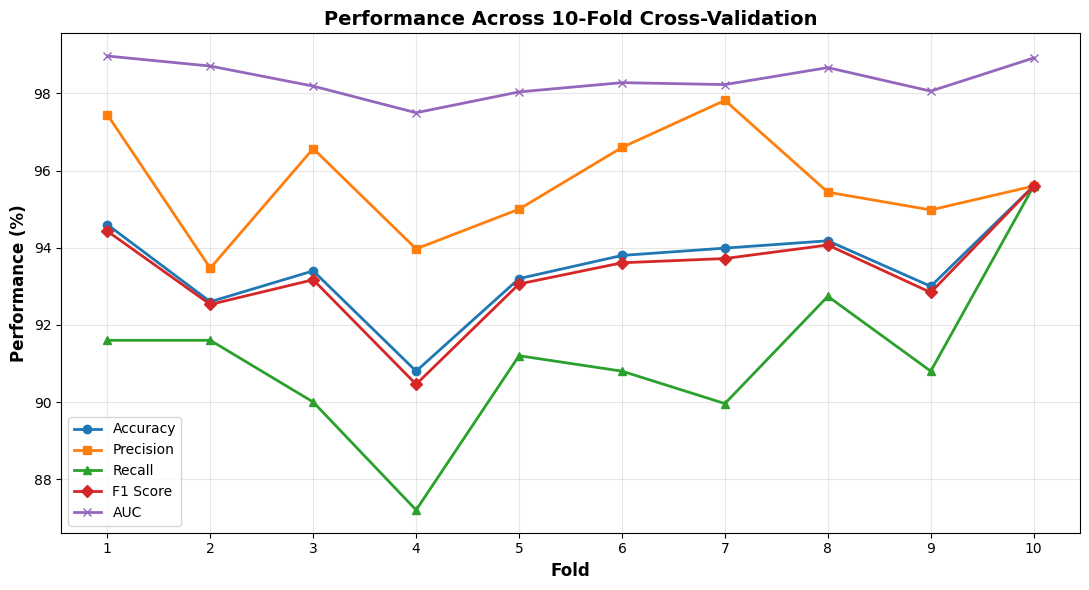

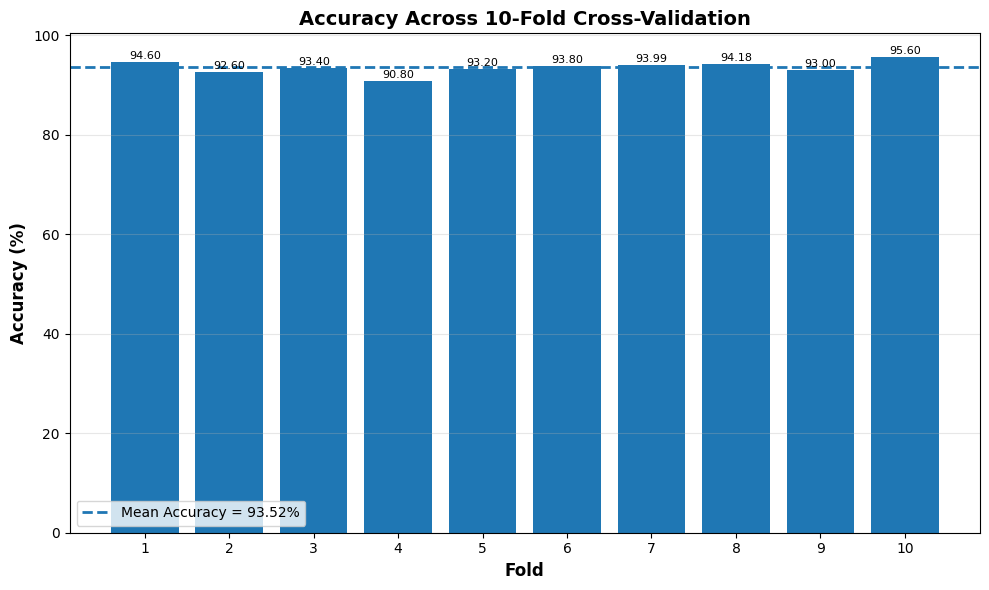

10-FOLD ACCURACY SUMMARY
Mean Accuracy      : 93.52%
Standard Deviation : 1.28%
Mean ± Std         : 93.52 ± 1.28%

Saved Figures:


/kaggle/working/10_fold_performance_comparison.png

/kaggle/working/10_fold_accuracy_bar_chart.png

In [61]:
# ============================================================
# CELL 25 : 10-FOLD PERFORMANCE COMPARISON GRAPH
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import FileLink, display

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------

folds = results_df["Fold"].values

accuracy = results_df["Accuracy"].values

# Convert decimal metrics to percentage for same-scale comparison
precision = results_df["Precision"].values * 100
recall = results_df["Recall"].values * 100
f1 = results_df["F1"].values * 100
auc = results_df["AUC"].values * 100

# ------------------------------------------------------------
# CREATE LINE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    folds,
    accuracy,
    marker="o",
    linewidth=2,
    label="Accuracy"
)

plt.plot(
    folds,
    precision,
    marker="s",
    linewidth=2,
    label="Precision"
)

plt.plot(
    folds,
    recall,
    marker="^",
    linewidth=2,
    label="Recall"
)

plt.plot(
    folds,
    f1,
    marker="D",
    linewidth=2,
    label="F1 Score"
)

plt.plot(
    folds,
    auc,
    marker="x",
    linewidth=2,
    label="AUC"
)

# ------------------------------------------------------------
# GRAPH FORMATTING
# ------------------------------------------------------------

plt.xlabel(
    "Fold",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Performance (%)",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Performance Across 10-Fold Cross-Validation",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(
    folds
)

plt.grid(
    alpha=0.3
)

plt.legend(
    loc="best"
)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE 300 DPI
# ------------------------------------------------------------

plt.savefig(
    "10_fold_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# MEAN ACCURACY BAR GRAPH
# ------------------------------------------------------------

mean_acc = results_df["Accuracy"].mean()
std_acc = results_df["Accuracy"].std(ddof=1)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    folds,
    accuracy
)

# Mean line
plt.axhline(
    mean_acc,
    linestyle="--",
    linewidth=2,
    label=f"Mean Accuracy = {mean_acc:.2f}%"
)

# Values above bars
for bar, value in zip(bars, accuracy):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.15,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.xlabel(
    "Fold",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Accuracy Across 10-Fold Cross-Validation",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(folds)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "10_fold_accuracy_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# PRINT SUMMARY
# ------------------------------------------------------------

print("="*60)
print("10-FOLD ACCURACY SUMMARY")
print("="*60)

print(f"Mean Accuracy      : {mean_acc:.2f}%")
print(f"Standard Deviation : {std_acc:.2f}%")
print(f"Mean ± Std         : {mean_acc:.2f} ± {std_acc:.2f}%")

print("="*60)

# ------------------------------------------------------------
# DOWNLOAD LINKS
# ------------------------------------------------------------

print("\nSaved Figures:")

display(
    FileLink(
        "10_fold_performance_comparison.png"
    )
)

display(
    FileLink(
        "10_fold_accuracy_bar_chart.png"
    )
)


STATISTICAL ANALYSIS OF 10-FOLD ACCURACY
Number of Folds           : 10
Mean Accuracy             : 93.5170%
Standard Deviation        : 1.2849%
Mean ± Std                : 93.5170 ± 1.2849%
Variance                  : 1.6511
Standard Error            : 0.4063
Median Accuracy           : 93.6000%
Minimum Accuracy          : 90.8000%
Maximum Accuracy          : 95.6000%
Degrees of Freedom        : 9
95% CI Lower Bound        : 92.5978%
95% CI Upper Bound        : 94.4362%
95% Confidence Interval   : [92.5978%, 94.4362%]
Margin of Error           : ±0.9192%

STATISTICAL SUMMARY TABLE


,Statistic,Value
0,Number of Folds,10.0000
1,Mean Accuracy (%),93.5170
2,Standard Deviation (%),1.2849
3,Variance,1.6511
4,Standard Error,0.4063
5,Median Accuracy (%),93.6000
6,Minimum Accuracy (%),90.8000
7,Maximum Accuracy (%),95.6000
8,95% CI Lower Bound (%),92.5978
9,95% CI Upper Bound (%),94.4362


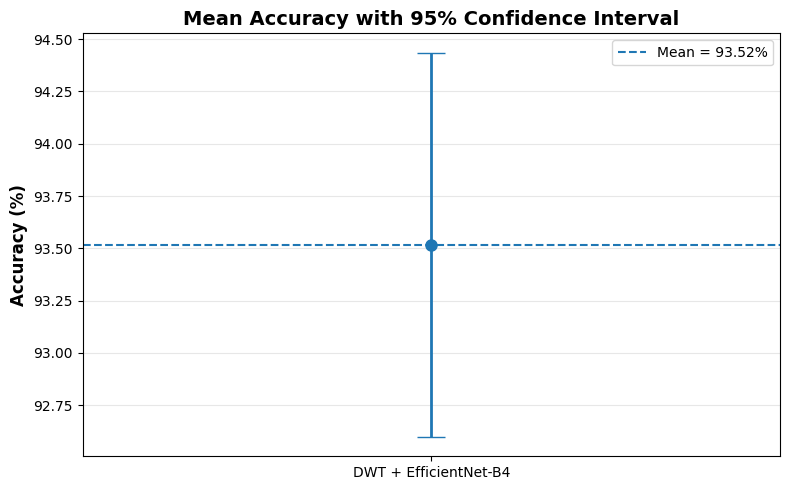


Files Saved Successfully:


/kaggle/working/statistical_analysis_10fold.csv

/kaggle/working/accuracy_95_confidence_interval.png

In [62]:
# ============================================================
# CELL 26 : STATISTICAL ANALYSIS + 95% CONFIDENCE INTERVAL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. GET 10-FOLD ACCURACIES
# ------------------------------------------------------------

accuracies = results_df["Accuracy"].astype(float).values

n = len(accuracies)

# ------------------------------------------------------------
# 2. BASIC STATISTICS
# ------------------------------------------------------------

mean_acc = np.mean(accuracies)

# Sample standard deviation
std_acc = np.std(
    accuracies,
    ddof=1
)

variance_acc = np.var(
    accuracies,
    ddof=1
)

standard_error = stats.sem(
    accuracies
)

median_acc = np.median(
    accuracies
)

min_acc = np.min(
    accuracies
)

max_acc = np.max(
    accuracies
)

# ------------------------------------------------------------
# 3. 95% CONFIDENCE INTERVAL
# ------------------------------------------------------------

confidence_level = 0.95

degrees_freedom = n - 1

t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    degrees_freedom
)

margin_error = (
    t_critical * standard_error
)

ci_lower = (
    mean_acc - margin_error
)

ci_upper = (
    mean_acc + margin_error
)

# ------------------------------------------------------------
# 4. PRINT STATISTICAL RESULTS
# ------------------------------------------------------------

print("\n" + "="*70)
print("STATISTICAL ANALYSIS OF 10-FOLD ACCURACY")
print("="*70)

print(f"Number of Folds           : {n}")

print(f"Mean Accuracy             : {mean_acc:.4f}%")

print(f"Standard Deviation        : {std_acc:.4f}%")

print(
    f"Mean ± Std                : "
    f"{mean_acc:.4f} ± {std_acc:.4f}%"
)

print(f"Variance                  : {variance_acc:.4f}")

print(f"Standard Error            : {standard_error:.4f}")

print(f"Median Accuracy           : {median_acc:.4f}%")

print(f"Minimum Accuracy          : {min_acc:.4f}%")

print(f"Maximum Accuracy          : {max_acc:.4f}%")

print(f"Degrees of Freedom        : {degrees_freedom}")

print(f"95% CI Lower Bound        : {ci_lower:.4f}%")

print(f"95% CI Upper Bound        : {ci_upper:.4f}%")

print(
    f"95% Confidence Interval   : "
    f"[{ci_lower:.4f}%, {ci_upper:.4f}%]"
)

print(f"Margin of Error           : ±{margin_error:.4f}%")

print("="*70)

# ------------------------------------------------------------
# 5. CREATE STATISTICAL SUMMARY TABLE
# ------------------------------------------------------------

statistical_summary = pd.DataFrame({

    "Statistic": [
        "Number of Folds",
        "Mean Accuracy (%)",
        "Standard Deviation (%)",
        "Variance",
        "Standard Error",
        "Median Accuracy (%)",
        "Minimum Accuracy (%)",
        "Maximum Accuracy (%)",
        "95% CI Lower Bound (%)",
        "95% CI Upper Bound (%)",
        "Margin of Error (%)"
    ],

    "Value": [
        n,
        mean_acc,
        std_acc,
        variance_acc,
        standard_error,
        median_acc,
        min_acc,
        max_acc,
        ci_lower,
        ci_upper,
        margin_error
    ]
})

print("\nSTATISTICAL SUMMARY TABLE")

display(
    statistical_summary.round(4)
)

# ------------------------------------------------------------
# 6. SAVE STATISTICAL TABLE CSV
# ------------------------------------------------------------

statistical_summary.to_csv(
    "statistical_analysis_10fold.csv",
    index=False
)

# ------------------------------------------------------------
# 7. CREATE CONFIDENCE INTERVAL FIGURE
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.errorbar(
    x=[1],
    y=[mean_acc],
    yerr=[margin_error],
    fmt="o",
    capsize=10,
    markersize=8,
    linewidth=2
)

plt.axhline(
    mean_acc,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean_acc:.2f}%"
)

plt.xlim(
    0.5,
    1.5
)

plt.xticks(
    [1],
    ["DWT + EfficientNet-B4"]
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Mean Accuracy with 95% Confidence Interval",
    fontsize=14,
    fontweight="bold"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

# ------------------------------------------------------------
# 8. SAVE FIGURE 300 DPI
# ------------------------------------------------------------

plt.savefig(
    "accuracy_95_confidence_interval.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. DOWNLOAD LINKS
# ------------------------------------------------------------

print("\nFiles Saved Successfully:")

display(
    FileLink(
        "statistical_analysis_10fold.csv"
    )
)

display(
    FileLink(
        "accuracy_95_confidence_interval.png"
    )
)

In [66]:
import os
import glob

saved_models = sorted(glob.glob("best_fold_*.pth"))

print("Saved models:")
for model_file in saved_models:
    print(model_file)

print("\nTotal saved models:", len(saved_models))

Saved models:
best_fold_1.pth
best_fold_10.pth
best_fold_2.pth
best_fold_3.pth
best_fold_4.pth
best_fold_5.pth
best_fold_6.pth
best_fold_7.pth
best_fold_8.pth
best_fold_9.pth

Total saved models: 10


In [67]:
# ============================================================
# COLLECT PREDICTIONS FROM ALL 10 SAVED FOLD MODELS
# ============================================================

import torch
import numpy as np

from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# 10-FOLD SETUP - SAME AS TRAINING
# ------------------------------------------------------------

kf_eval = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Store predictions from ALL folds
all_y_true = []
all_y_pred = []
all_y_prob = []

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("GENERATING PREDICTIONS FROM SAVED 10-FOLD MODELS")
print("=" * 70)

# ------------------------------------------------------------
# LOOP THROUGH SAME 10 FOLDS
# ------------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(
    kf_eval.split(video_names, video_labels),
    start=1
):

    print(f"\nProcessing Fold {fold}/10...")

    # --------------------------------------------------------
    # Re-create validation samples
    # SAME 5-frame validation used during training
    # --------------------------------------------------------

    val_samples = build_frame_samples(
        video_names[val_idx],
        video_labels[val_idx]
    )

    val_dataset = DeepfakeDataset(
        val_samples,
        val_transform
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=16,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    # --------------------------------------------------------
    # CREATE MODEL
    # --------------------------------------------------------

    model = create_model()

    # --------------------------------------------------------
    # LOAD SAVED BEST MODEL FOR THIS FOLD
    # --------------------------------------------------------

    model_path = f"best_fold_{fold}.pth"

    model.load_state_dict(
        torch.load(
            model_path,
            map_location=device
        )
    )

    model = model.to(device)

    model.eval()

    fold_y_true = []
    fold_y_pred = []
    fold_y_prob = []

    # --------------------------------------------------------
    # INFERENCE ONLY - NO TRAINING
    # --------------------------------------------------------

    with torch.no_grad():

        for images, labels, _ in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            fake_probability = probabilities[:, 1]

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            fold_y_true.extend(
                labels.cpu().numpy()
            )

            fold_y_pred.extend(
                predictions.cpu().numpy()
            )

            fold_y_prob.extend(
                fake_probability.cpu().numpy()
            )

    # --------------------------------------------------------
    # ADD THIS FOLD TO OVERALL RESULTS
    # --------------------------------------------------------

    all_y_true.extend(fold_y_true)
    all_y_pred.extend(fold_y_pred)
    all_y_prob.extend(fold_y_prob)

    print(
        f"Fold {fold} completed | "
        f"Samples = {len(fold_y_true)}"
    )

# ------------------------------------------------------------
# CONVERT TO NUMPY
# ------------------------------------------------------------

all_y_true = np.array(all_y_true)

all_y_pred = np.array(all_y_pred)

all_y_prob = np.array(all_y_prob)

# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("ALL 10 FOLDS PREDICTIONS COLLECTED")

print("=" * 70)

print(
    "Total True Labels       :",
    len(all_y_true)
)

print(
    "Total Predictions       :",
    len(all_y_pred)
)

print(
    "Total Probabilities     :",
    len(all_y_prob)
)

print(
    "Real Samples            :",
    np.sum(all_y_true == 0)
)

print(
    "Fake Samples            :",
    np.sum(all_y_true == 1)
)

print("=" * 70)

GENERATING PREDICTIONS FROM SAVED 10-FOLD MODELS

Processing Fold 1/10...
Fold 1 completed | Samples = 500

Processing Fold 2/10...
Fold 2 completed | Samples = 500

Processing Fold 3/10...
Fold 3 completed | Samples = 500

Processing Fold 4/10...
Fold 4 completed | Samples = 500

Processing Fold 5/10...
Fold 5 completed | Samples = 500

Processing Fold 6/10...
Fold 6 completed | Samples = 500

Processing Fold 7/10...
Fold 7 completed | Samples = 499

Processing Fold 8/10...
Fold 8 completed | Samples = 498

Processing Fold 9/10...
Fold 9 completed | Samples = 500

Processing Fold 10/10...
Fold 10 completed | Samples = 500

ALL 10 FOLDS PREDICTIONS COLLECTED
Total True Labels       : 4997
Total Predictions       : 4997
Total Probabilities     : 4997
Real Samples            : 2500
Fake Samples            : 2497



OVERALL 10-FOLD COMBINED PERFORMANCE
Accuracy          : 93.52%
Precision         : 0.9567
Recall            : 0.9115
F1 Score          : 0.9336
ROC-AUC           : 0.9835
Average Precision : 0.9841

Confusion Matrix:
[[2397  103]
 [ 221 2276]]


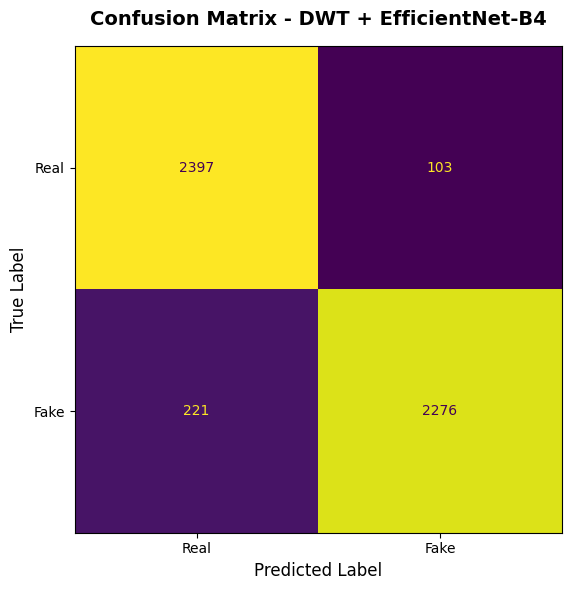

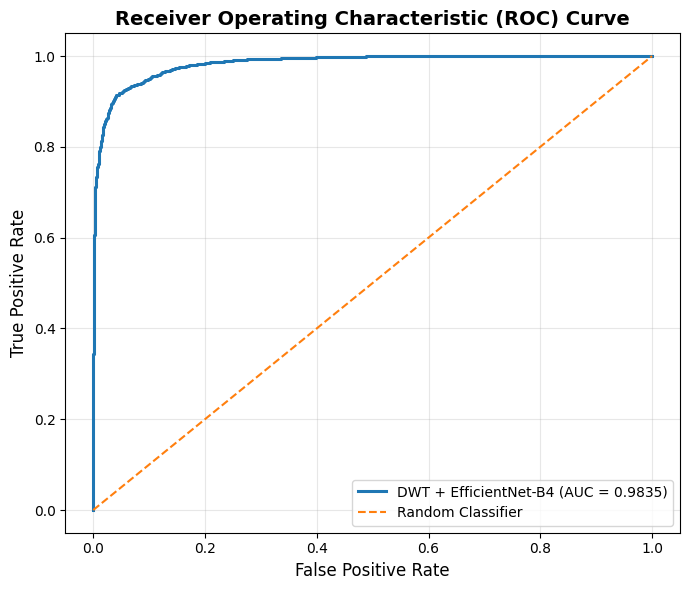

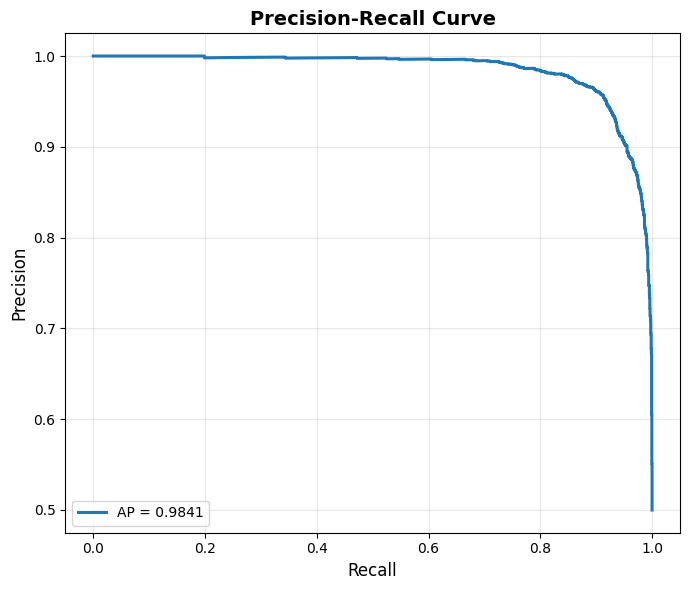


OVERALL PERFORMANCE TABLE


,Metric,Value
0,Accuracy (%),93.5161
1,Precision,0.9567
2,Recall,0.9115
3,F1 Score,0.9336
4,ROC-AUC,0.9835
5,Average Precision,0.9841



FILES SAVED SUCCESSFULLY
1. overall_confusion_matrix.png
2. overall_roc_curve.png
3. overall_precision_recall_curve.png
4. overall_10fold_metrics.csv
5. 10fold_predictions.csv

DOWNLOAD:


/kaggle/working/overall_confusion_matrix.png

/kaggle/working/overall_roc_curve.png

/kaggle/working/overall_precision_recall_curve.png

/kaggle/working/overall_10fold_metrics.csv

/kaggle/working/10fold_predictions.csv

In [68]:
# ============================================================
# PAPER-READY EVALUATION FIGURES
# CONFUSION MATRIX + ROC + PRECISION-RECALL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from IPython.display import display, FileLink


# ============================================================
# 1. OVERALL METRICS
# ============================================================

overall_accuracy = accuracy_score(
    all_y_true,
    all_y_pred
)

overall_precision = precision_score(
    all_y_true,
    all_y_pred,
    zero_division=0
)

overall_recall = recall_score(
    all_y_true,
    all_y_pred,
    zero_division=0
)

overall_f1 = f1_score(
    all_y_true,
    all_y_pred,
    zero_division=0
)

overall_auc = roc_auc_score(
    all_y_true,
    all_y_prob
)

average_precision = average_precision_score(
    all_y_true,
    all_y_prob
)


print("\n" + "="*70)
print("OVERALL 10-FOLD COMBINED PERFORMANCE")
print("="*70)

print(f"Accuracy          : {overall_accuracy*100:.2f}%")
print(f"Precision         : {overall_precision:.4f}")
print(f"Recall            : {overall_recall:.4f}")
print(f"F1 Score          : {overall_f1:.4f}")
print(f"ROC-AUC           : {overall_auc:.4f}")
print(f"Average Precision : {average_precision:.4f}")

print("="*70)


# ============================================================
# 2. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_y_true,
    all_y_pred
)

print("\nConfusion Matrix:")
print(cm)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Confusion Matrix - DWT + EfficientNet-B4",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Predicted Label",
    fontsize=12
)

ax.set_ylabel(
    "True Label",
    fontsize=12
)

plt.tight_layout()

plt.savefig(
    "overall_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. ROC CURVE
# ============================================================

fpr, tpr, roc_thresholds = roc_curve(
    all_y_true,
    all_y_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    linewidth=2.2,
    label=f"DWT + EfficientNet-B4 (AUC = {overall_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "Receiver Operating Characteristic (ROC) Curve",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "overall_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. PRECISION-RECALL CURVE
# ============================================================

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    all_y_true,
    all_y_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    pr_recall,
    pr_precision,
    linewidth=2.2,
    label=f"AP = {average_precision:.4f}"
)

plt.xlabel(
    "Recall",
    fontsize=12
)

plt.ylabel(
    "Precision",
    fontsize=12
)

plt.title(
    "Precision-Recall Curve",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    loc="lower left"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "overall_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. CREATE OVERALL METRICS TABLE
# ============================================================

overall_metrics_df = pd.DataFrame({

    "Metric": [
        "Accuracy (%)",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision"
    ],

    "Value": [
        overall_accuracy * 100,
        overall_precision,
        overall_recall,
        overall_f1,
        overall_auc,
        average_precision
    ]

})

print("\nOVERALL PERFORMANCE TABLE")

display(
    overall_metrics_df.round(4)
)


# ============================================================
# 6. SAVE RESULTS CSV
# ============================================================

overall_metrics_df.to_csv(
    "overall_10fold_metrics.csv",
    index=False
)


# ============================================================
# 7. SAVE RAW PREDICTIONS
# Important for later statistical analysis/reproducibility
# ============================================================

prediction_df = pd.DataFrame({

    "True_Label": all_y_true,
    "Predicted_Label": all_y_pred,
    "Fake_Probability": all_y_prob

})

prediction_df.to_csv(
    "10fold_predictions.csv",
    index=False
)


# ============================================================
# 8. DOWNLOAD LINKS
# ============================================================

print("\n" + "="*70)
print("FILES SAVED SUCCESSFULLY")
print("="*70)

print("1. overall_confusion_matrix.png")
print("2. overall_roc_curve.png")
print("3. overall_precision_recall_curve.png")
print("4. overall_10fold_metrics.csv")
print("5. 10fold_predictions.csv")

print("\nDOWNLOAD:")

display(
    FileLink("overall_confusion_matrix.png")
)

display(
    FileLink("overall_roc_curve.png")
)

display(
    FileLink("overall_precision_recall_curve.png")
)

display(
    FileLink("overall_10fold_metrics.csv")
)

display(
    FileLink("10fold_predictions.csv")
)

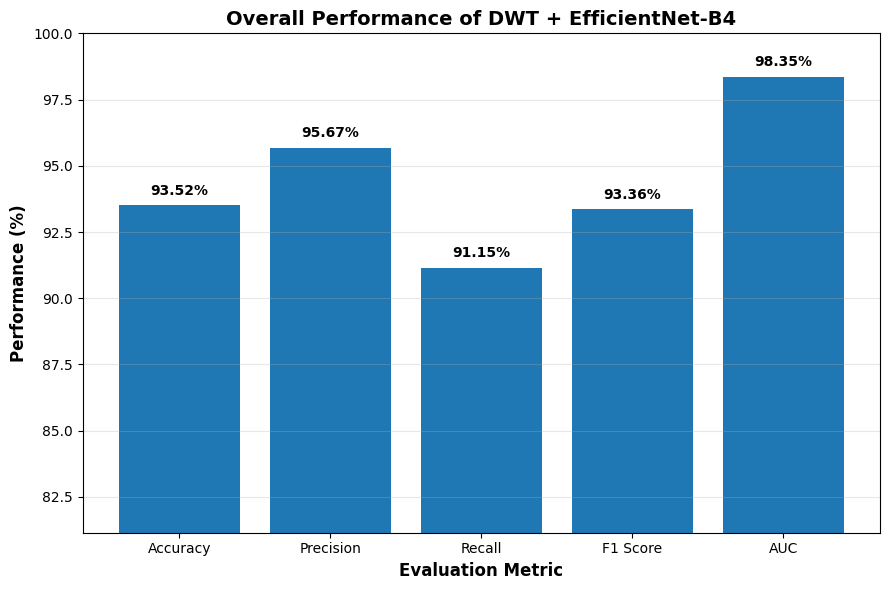

Saved: overall_metrics_bar_chart.png


/kaggle/working/overall_metrics_bar_chart.png

In [69]:
# ============================================================
# CELL 30 : OVERALL METRICS BAR CHART
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from IPython.display import display, FileLink

# Calculate metrics
acc = accuracy_score(all_y_true, all_y_pred) * 100
prec = precision_score(all_y_true, all_y_pred) * 100
rec = recall_score(all_y_true, all_y_pred) * 100
f1 = f1_score(all_y_true, all_y_pred) * 100
auc = roc_auc_score(all_y_true, all_y_prob) * 100

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC"
]

values = [
    acc,
    prec,
    rec,
    f1,
    auc
]

# Plot
plt.figure(figsize=(9, 6))

bars = plt.bar(
    metrics,
    values
)

# Add values above bars
for bar, value in zip(bars, values):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.4,
        f"{value:.2f}%",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.ylabel(
    "Performance (%)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Evaluation Metric",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Overall Performance of DWT + EfficientNet-B4",
    fontsize=14,
    fontweight="bold"
)

# Give room above bars
plt.ylim(
    max(0, min(values) - 10),
    min(100, max(values) + 5)
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "overall_metrics_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: overall_metrics_bar_chart.png")

display(
    FileLink("overall_metrics_bar_chart.png")
)

Image used:
/kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/original/000/frame_1.jpg


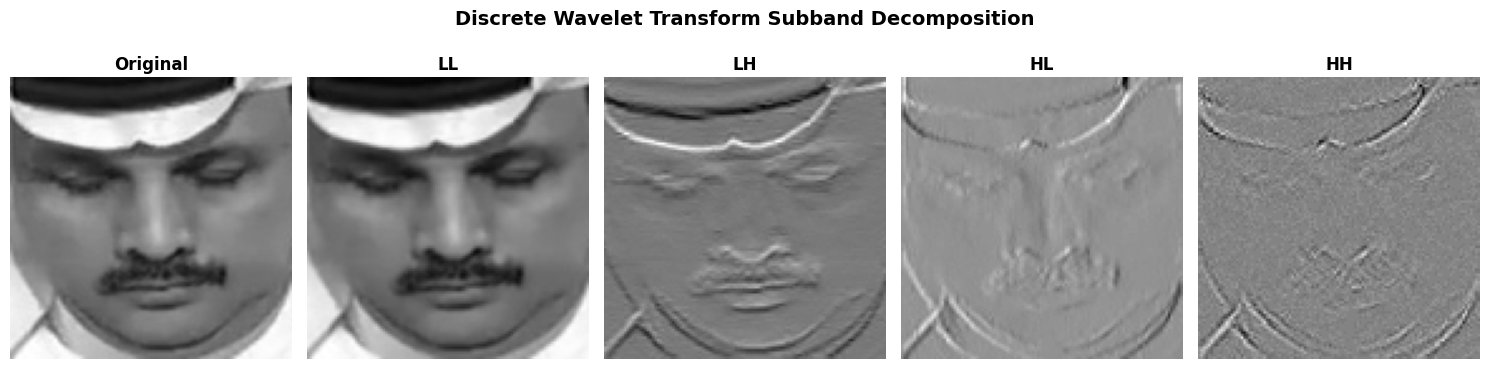

Saved: dwt_subband_visualization.png


/kaggle/working/dwt_subband_visualization.png

In [70]:
# ============================================================
# CELL 31 : DWT SUBBAND VISUALIZATION
# Original + LL + LH + HL + HH
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pywt
from PIL import Image
from IPython.display import display, FileLink

# ------------------------------------------------------------
# GET ONE REAL DATASET IMAGE
# ------------------------------------------------------------

# First sample path from your existing samples
sample_path = results_sample_path if "results_sample_path" in globals() else None

if sample_path is None:

    # Try getting an image from the existing frame samples
    try:
        temp_samples = build_frame_samples(
            video_names[:1],
            video_labels[:1]
        )

        sample_path = temp_samples[0][0]

    except Exception as e:
        raise RuntimeError(
            "Could not automatically locate sample image. "
            "Set sample_path manually to one aligned face image."
        )

print("Image used:")
print(sample_path)

# ------------------------------------------------------------
# LOAD IMAGE
# ------------------------------------------------------------

img = Image.open(
    sample_path
).convert("L")

img_np = np.array(img)

# ------------------------------------------------------------
# APPLY 2D DWT
# ------------------------------------------------------------

LL, (LH, HL, HH) = pywt.dwt2(
    img_np,
    "haar"
)

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    5,
    figsize=(15, 4)
)

axes[0].imshow(
    img_np,
    cmap="gray"
)

axes[0].set_title(
    "Original",
    fontweight="bold"
)

axes[1].imshow(
    LL,
    cmap="gray"
)

axes[1].set_title(
    "LL",
    fontweight="bold"
)

axes[2].imshow(
    LH,
    cmap="gray"
)

axes[2].set_title(
    "LH",
    fontweight="bold"
)

axes[3].imshow(
    HL,
    cmap="gray"
)

axes[3].set_title(
    "HL",
    fontweight="bold"
)

axes[4].imshow(
    HH,
    cmap="gray"
)

axes[4].set_title(
    "HH",
    fontweight="bold"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    "Discrete Wavelet Transform Subband Decomposition",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "dwt_subband_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: dwt_subband_visualization.png")

display(
    FileLink("dwt_subband_visualization.png")
)

Model loaded successfully.
Grad-CAM target layer: features.8.0
Sample: /kaggle/input/datasets/srujanamannepuli/deepfake-aligned-faces-5-frames/aligned_faces/original/000/frame_1.jpg
True Label: Real
Predicted: Real
Confidence: 99.05%


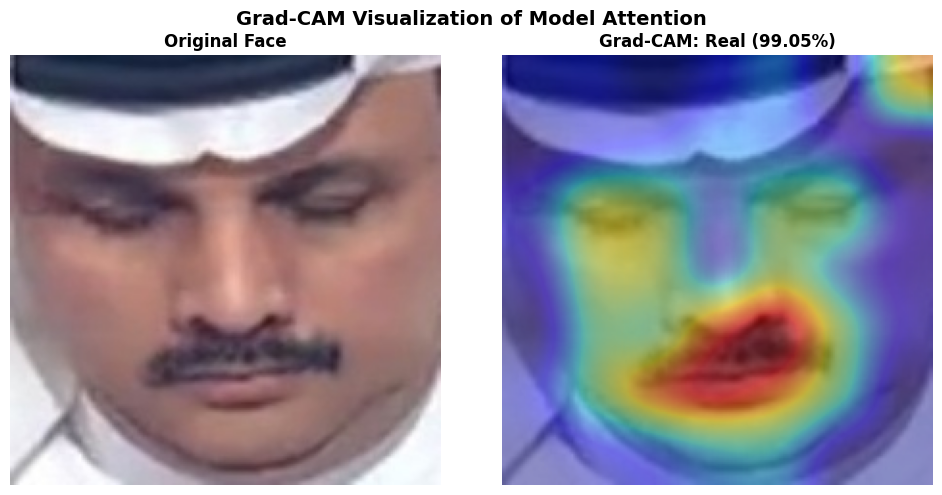

Saved: gradcam_visualization.png


/kaggle/working/gradcam_visualization.png

In [71]:
# ============================================================
# CELL 32 : GRAD-CAM VISUALIZATION
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, FileLink

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# LOAD BEST SAVED MODEL
# ------------------------------------------------------------

gradcam_model = create_model()

gradcam_model.load_state_dict(
    torch.load(
        "best_fold_1.pth",
        map_location=device
    )
)

gradcam_model = gradcam_model.to(device)

gradcam_model.eval()

print("Model loaded successfully.")

# ------------------------------------------------------------
# FIND LAST CONVOLUTION LAYER AUTOMATICALLY
# ------------------------------------------------------------

target_layer = None
target_layer_name = None

for name, module in gradcam_model.named_modules():

    if isinstance(module, torch.nn.Conv2d):

        target_layer = module
        target_layer_name = name

if target_layer is None:

    raise RuntimeError(
        "No Conv2d layer found in model."
    )

print(
    "Grad-CAM target layer:",
    target_layer_name
)

# ------------------------------------------------------------
# STORAGE
# ------------------------------------------------------------

activations = []
gradients = []

# ------------------------------------------------------------
# HOOK FUNCTIONS
# ------------------------------------------------------------

def forward_hook(module, input, output):

    activations.clear()

    activations.append(
        output.detach()
    )


def backward_hook(module, grad_input, grad_output):

    gradients.clear()

    gradients.append(
        grad_output[0].detach()
    )


forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

# ------------------------------------------------------------
# GET ONE SAMPLE IMAGE
# ------------------------------------------------------------

temp_samples = build_frame_samples(
    video_names[:1],
    video_labels[:1]
)

sample_path = temp_samples[0][0]

true_label = temp_samples[0][1]

print(
    "Sample:",
    sample_path
)

print(
    "True Label:",
    "Fake" if true_label == 1 else "Real"
)

# ------------------------------------------------------------
# LOAD ORIGINAL IMAGE
# ------------------------------------------------------------

original_image = Image.open(
    sample_path
).convert("RGB")

# ------------------------------------------------------------
# APPLY SAME DWT + VALIDATION TRANSFORM
# ------------------------------------------------------------

# Create temporary dataset so EXACT SAME preprocessing is used
temp_dataset = DeepfakeDataset(
    [temp_samples[0]],
    val_transform
)

input_tensor, _, _ = temp_dataset[0]

input_tensor = input_tensor.unsqueeze(0).to(device)

# ------------------------------------------------------------
# FORWARD PASS
# ------------------------------------------------------------

gradcam_model.zero_grad()

output = gradcam_model(
    input_tensor
)

probabilities = torch.softmax(
    output,
    dim=1
)

predicted_class = torch.argmax(
    output,
    dim=1
).item()

confidence = probabilities[
    0,
    predicted_class
].item()

print(
    "Predicted:",
    "Fake" if predicted_class == 1 else "Real"
)

print(
    f"Confidence: {confidence*100:.2f}%"
)

# ------------------------------------------------------------
# BACKWARD PASS
# ------------------------------------------------------------

score = output[
    0,
    predicted_class
]

score.backward()

# ------------------------------------------------------------
# GENERATE GRAD-CAM
# ------------------------------------------------------------

activation = activations[0]

gradient = gradients[0]

weights = gradient.mean(
    dim=(2, 3),
    keepdim=True
)

cam = (
    weights * activation
).sum(
    dim=1
)

cam = torch.relu(
    cam
)

cam = cam.squeeze().cpu().numpy()

# Normalize
cam = cam - cam.min()

if cam.max() > 0:

    cam = cam / cam.max()

# ------------------------------------------------------------
# RESIZE HEATMAP
# ------------------------------------------------------------

cam_image = Image.fromarray(
    np.uint8(cam * 255)
)

cam_image = cam_image.resize(
    original_image.size
)

cam_resized = np.array(
    cam_image
) / 255.0

original_np = np.array(
    original_image
)

# ------------------------------------------------------------
# PLOT ORIGINAL + GRAD-CAM
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(
    original_np
)

axes[0].set_title(
    "Original Face",
    fontweight="bold"
)

axes[0].axis("off")

axes[1].imshow(
    original_np
)

axes[1].imshow(
    cam_resized,
    cmap="jet",
    alpha=0.45
)

axes[1].set_title(
    f"Grad-CAM: {'Fake' if predicted_class == 1 else 'Real'} "
    f"({confidence*100:.2f}%)",
    fontweight="bold"
)

axes[1].axis("off")

plt.suptitle(
    "Grad-CAM Visualization of Model Attention",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "gradcam_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# REMOVE HOOKS
# ------------------------------------------------------------

forward_handle.remove()
backward_handle.remove()

print(
    "Saved: gradcam_visualization.png"
)

display(
    FileLink(
        "gradcam_visualization.png"
    )
)